In [1]:

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.base import clone

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt
import seaborn as sns

# Cargar datos
df = pd.read_csv('/content/EngineFaultDB_Final.csv')

# Separar variables predictoras y objetivo
X = df.drop(columns=['Fault'])
y = df['Fault'].astype(int)

print("Dimensiones:", X.shape)
print("\nDistribución de clases:")
print(y.value_counts().sort_index())

# Primera división: 80% desarrollo, 20% test
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Segunda división: 75% train, 25% validation del conjunto de desarrollo
# Resultado final: 60% train, 20% validation, 20% test
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev,
    test_size=0.25,
    random_state=42,
    stratify=y_dev
)

print("\nTamaños:")
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Dimensiones: (55999, 14)

Distribución de clases:
Fault
0    16000
1    10998
2    15000
3    14001
Name: count, dtype: int64

Tamaños:
Train: (33599, 14)
Validation: (11200, 14)
Test: (11200, 14)


In [2]:

models = {
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(
            kernel="rbf",
            C=1.0,
            gamma="scale",
            probability=True,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "MLP": Pipeline([
        ("scaler", StandardScaler()),
        ("model", MLPClassifier(
            hidden_layer_sizes=(100, 50),
            activation="relu",
            solver="adam",
            alpha=0.0001,
            learning_rate_init=0.001,
            max_iter=500,
            early_stopping=True,
            random_state=42
        ))
    ])
}


In [3]:

baseline_models = {}

for name, model in models.items():

    clf = clone(model)
    clf.fit(X_train, y_train)

    baseline_models[name] = clf

    pred = clf.predict(X_val)

    print(f"\n===== BASELINE {name} =====")
    print("Accuracy:", accuracy_score(y_val, pred))
    print("F1 macro:", f1_score(y_val, pred, average="macro"))

    print(classification_report(y_val, pred))



===== BASELINE SVM =====
Accuracy: 0.749375
F1 macro: 0.6975274697063852
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      3200
           1       0.99      1.00      0.99      2200
           2       1.00      0.07      0.13      3000
           3       0.50      1.00      0.67      2800

    accuracy                           0.75     11200
   macro avg       0.87      0.77      0.70     11200
weighted avg       0.87      0.75      0.68     11200


===== BASELINE MLP =====
Accuracy: 0.7467857142857143
F1 macro: 0.7543150827223879
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      3200
           1       0.98      1.00      0.99      2200
           2       0.53      0.49      0.51      3000
           3       0.50      0.54      0.52      2800

    accuracy                           0.75     11200
   macro avg       0.75      0.76      0.75     11200
weighted avg       0.75    

In [4]:

# Seleccionar exclusivamente las clases 2 y 3
mask_train = y_train.isin([2, 3])
mask_val = y_val.isin([2, 3])

X_train_23 = X_train.loc[mask_train]
y_train_23 = y_train.loc[mask_train]

X_val_23 = X_val.loc[mask_val]
y_val_23 = y_val.loc[mask_val]

specialist_models = {}

for name, model in models.items():

    clf = clone(model)
    clf.fit(X_train_23, y_train_23)

    specialist_models[name] = clf

    pred = clf.predict(X_val_23)

    print(f"\n===== ESPECIALISTA 2 VS 3: {name} =====")
    print("Accuracy:", accuracy_score(y_val_23, pred))
    print("F1 macro:", f1_score(y_val_23, pred, average="macro"))

    print(classification_report(
        y_val_23,
        pred,
        labels=[2, 3],
        target_names=[
            "Clase 2 - Mezcla baja aire-combustible",
            "Clase 3 - Bajo voltaje"
        ]
    ))



===== ESPECIALISTA 2 VS 3: SVM =====
Accuracy: 0.5181034482758621
F1 macro: 0.39957193341948694
                                        precision    recall  f1-score   support

Clase 2 - Mezcla baja aire-combustible       0.96      0.07      0.13      3000
                Clase 3 - Bajo voltaje       0.50      1.00      0.67      2800

                              accuracy                           0.52      5800
                             macro avg       0.73      0.53      0.40      5800
                          weighted avg       0.74      0.52      0.39      5800


===== ESPECIALISTA 2 VS 3: MLP =====
Accuracy: 0.5182758620689655
F1 macro: 0.4829515549613321
                                        precision    recall  f1-score   support

Clase 2 - Mezcla baja aire-combustible       0.58      0.25      0.35      3000
                Clase 3 - Bajo voltaje       0.50      0.81      0.62      2800

                              accuracy                           0.52      5800
  

In [5]:

# Transformación de las etiquetas para la primera etapa:
# 0 -> 0
# 1 -> 1
# 2 -> 23
# 3 -> 23

def transformar_etiquetas(y):
    return y.map({0: 0, 1: 1, 2: 23, 3: 23})


hierarchical_models = {}

for name, model in models.items():

    # Primera etapa: 0, 1 y grupo 23
    y_train_stage1 = transformar_etiquetas(y_train)

    stage1 = clone(model)
    stage1.fit(X_train, y_train_stage1)

    # Segunda etapa: especialista 2 vs 3
    mask = y_train.isin([2, 3])

    stage2 = clone(model)
    stage2.fit(X_train.loc[mask], y_train.loc[mask])

    hierarchical_models[name] = {
        "stage1": stage1,
        "stage2": stage2
    }


def predict_hierarchical(hierarchical_model, X):

    stage1 = hierarchical_model["stage1"]
    stage2 = hierarchical_model["stage2"]

    # Probabilidades de la primera etapa
    p_stage1 = stage1.predict_proba(X)
    classes_stage1 = list(stage1.classes_)

    # Probabilidades del especialista
    p_stage2 = stage2.predict_proba(X)
    classes_stage2 = list(stage2.classes_)

    # Construir probabilidades para las cuatro clases originales
    probabilities = np.zeros((len(X), 4))

    # Clase 0
    probabilities[:, 0] = p_stage1[:, classes_stage1.index(0)]

    # Clase 1
    probabilities[:, 1] = p_stage1[:, classes_stage1.index(1)]

    # Probabilidad de pertenecer al grupo 2-3
    p_group23 = p_stage1[:, classes_stage1.index(23)]

    # Distribuir la probabilidad del grupo entre 2 y 3
    probabilities[:, 2] = (
        p_group23 * p_stage2[:, classes_stage2.index(2)]
    )

    probabilities[:, 3] = (
        p_group23 * p_stage2[:, classes_stage2.index(3)]
    )

    predictions = np.argmax(probabilities, axis=1)

    return predictions, probabilities


In [6]:

for name, hierarchical_model in hierarchical_models.items():

    pred, probabilities = predict_hierarchical(
        hierarchical_model,
        X_val
    )

    print(f"\n===== JERÁRQUICO {name} =====")
    print("Accuracy:", accuracy_score(y_val, pred))
    print("F1 macro:", f1_score(y_val, pred, average="macro"))

    print(classification_report(
        y_val,
        pred,
        labels=[0, 1, 2, 3]
    ))



===== JERÁRQUICO SVM =====
Accuracy: 0.7458928571428571
F1 macro: 0.7504008703437943
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      3200
           1       1.00      1.00      1.00      2200
           2       0.54      0.37      0.44      3000
           3       0.49      0.66      0.57      2800

    accuracy                           0.75     11200
   macro avg       0.76      0.76      0.75     11200
weighted avg       0.75      0.75      0.74     11200


===== JERÁRQUICO MLP =====
Accuracy: 0.7503571428571428
F1 macro: 0.7412581332765001
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      3200
           1       1.00      1.00      1.00      2200
           2       0.58      0.25      0.35      3000
           3       0.50      0.81      0.62      2800

    accuracy                           0.75     11200
   macro avg       0.77      0.76      0.74     11200
weighted avg 

In [7]:

results = []

for name in models.keys():

    # Modelo convencional
    baseline = baseline_models[name]
    pred_baseline = baseline.predict(X_test)

    results.append({
        "Modelo": f"Baseline {name}",
        "Accuracy": accuracy_score(y_test, pred_baseline),
        "F1 macro": f1_score(y_test, pred_baseline, average="macro")
    })

    # Modelo jerárquico
    hierarchical = hierarchical_models[name]
    pred_hierarchical, probabilities = predict_hierarchical(
        hierarchical,
        X_test
    )

    results.append({
        "Modelo": f"Jerárquico {name}",
        "Accuracy": accuracy_score(y_test, pred_hierarchical),
        "F1 macro": f1_score(y_test, pred_hierarchical, average="macro")
    })

results_df = pd.DataFrame(results)

print(results_df.sort_values("F1 macro", ascending=False).to_string(index=False))


        Modelo  Accuracy  F1 macro
Jerárquico SVM  0.747679  0.752291
  Baseline MLP  0.741607  0.749799
Jerárquico MLP  0.747411  0.737837
  Baseline SVM  0.748214  0.695373


In [8]:

mask_test_23 = y_test.isin([2, 3])

X_test_23 = X_test.loc[mask_test_23]
y_test_23 = y_test.loc[mask_test_23]

for name, specialist in specialist_models.items():

    pred = specialist.predict(X_test_23)

    print(f"\n===== ESPECIALISTA {name} EN TEST =====")
    print("Accuracy:", accuracy_score(y_test_23, pred))
    print("F1 macro:", f1_score(y_test_23, pred, average="macro"))

    print(classification_report(
        y_test_23,
        pred,
        labels=[2, 3],
        target_names=[
            "Mezcla baja aire-combustible",
            "Bajo voltaje"
        ]
    ))



===== ESPECIALISTA SVM EN TEST =====
Accuracy: 0.5162068965517241
F1 macro: 0.3945386904761905
                              precision    recall  f1-score   support

Mezcla baja aire-combustible       0.98      0.07      0.12      3000
                Bajo voltaje       0.50      1.00      0.67      2800

                    accuracy                           0.52      5800
                   macro avg       0.74      0.53      0.39      5800
                weighted avg       0.75      0.52      0.39      5800


===== ESPECIALISTA MLP EN TEST =====
Accuracy: 0.5124137931034483
F1 macro: 0.4759465927135285
                              precision    recall  f1-score   support

Mezcla baja aire-combustible       0.57      0.24      0.34      3000
                Bajo voltaje       0.50      0.80      0.61      2800

                    accuracy                           0.51      5800
                   macro avg       0.53      0.52      0.48      5800
                weighted avg     

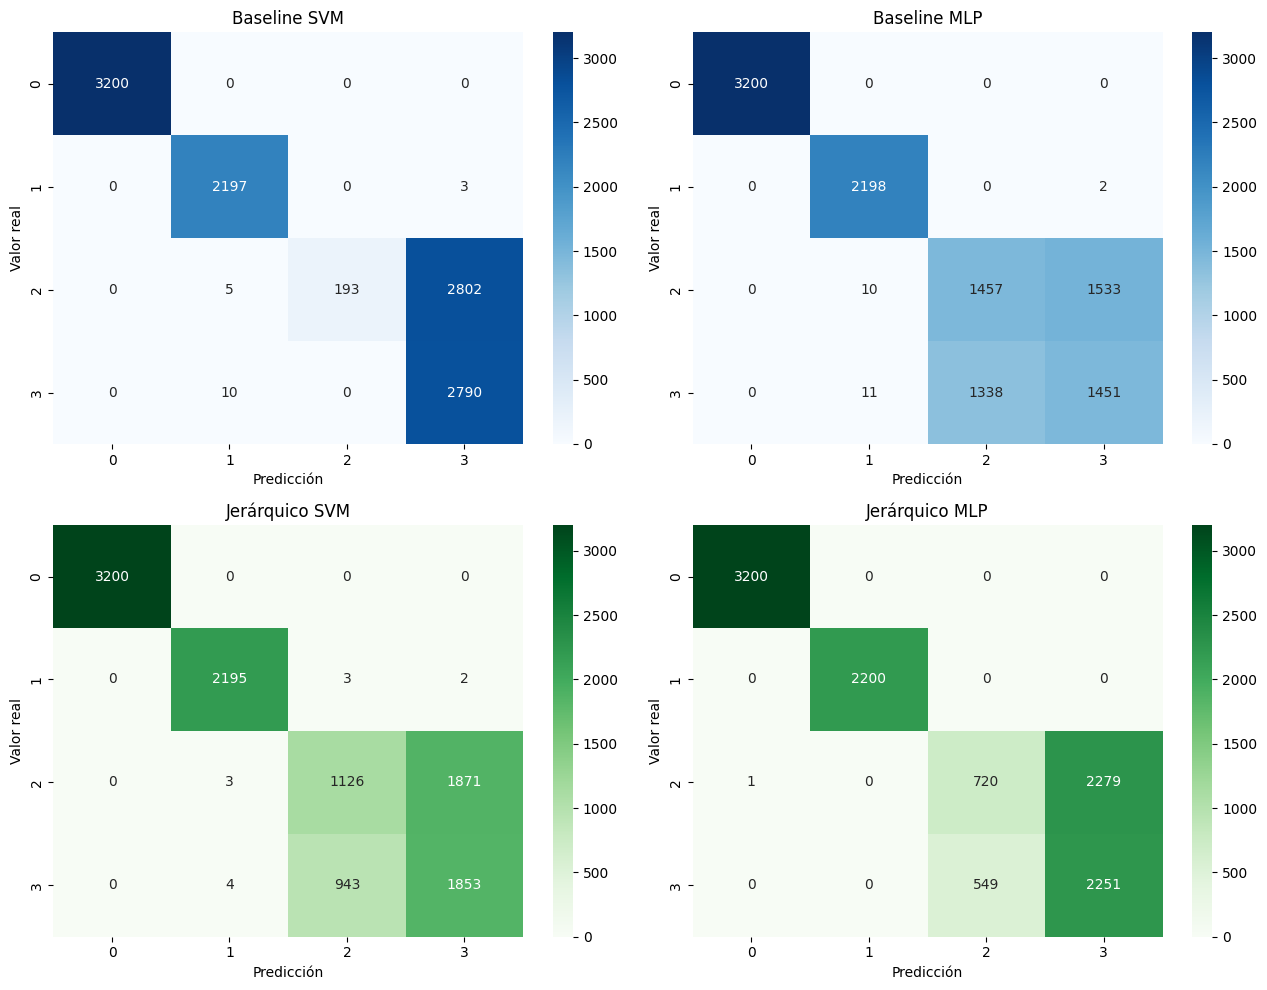

In [9]:

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

for ax, name in zip(axes.ravel(), ["SVM", "MLP"]):

    # Baseline
    pred_base = baseline_models[name].predict(X_test)

    cm_base = confusion_matrix(
        y_test, pred_base, labels=[0, 1, 2, 3]
    )

    sns.heatmap(
        cm_base,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax,
        xticklabels=[0, 1, 2, 3],
        yticklabels=[0, 1, 2, 3]
    )

    ax.set_title(f"Baseline {name}")
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Valor real")

for ax, name in zip(axes.ravel()[2:], ["SVM", "MLP"]):

    # Jerárquico
    pred_hier, _ = predict_hierarchical(
        hierarchical_models[name],
        X_test
    )

    cm_hier = confusion_matrix(
        y_test, pred_hier, labels=[0, 1, 2, 3]
    )

    sns.heatmap(
        cm_hier,
        annot=True,
        fmt="d",
        cmap="Greens",
        ax=ax,
        xticklabels=[0, 1, 2, 3],
        yticklabels=[0, 1, 2, 3]
    )

    ax.set_title(f"Jerárquico {name}")
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Valor real")

plt.tight_layout()
plt.show()


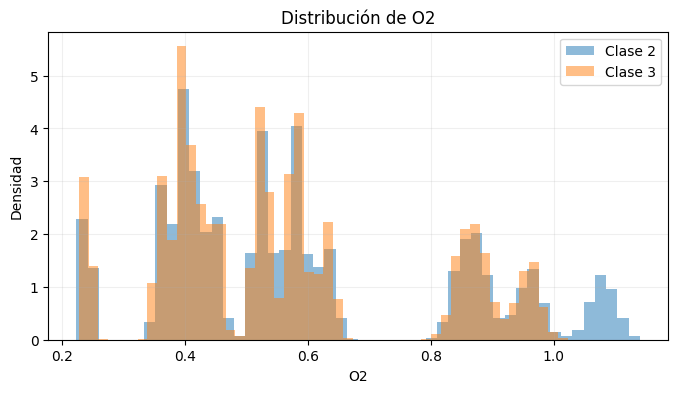

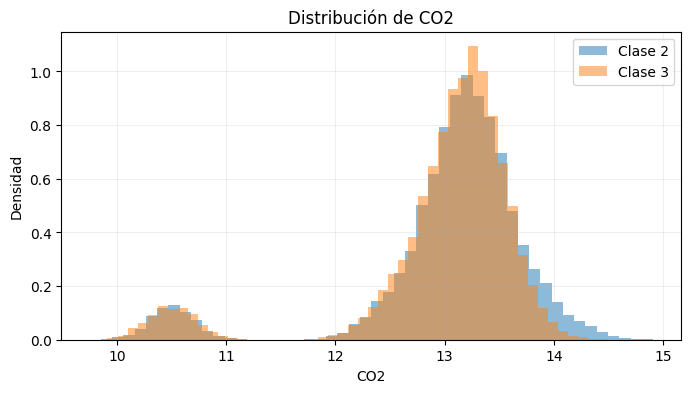

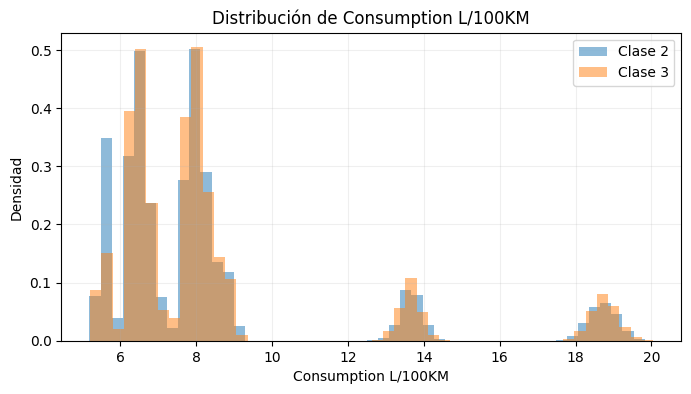

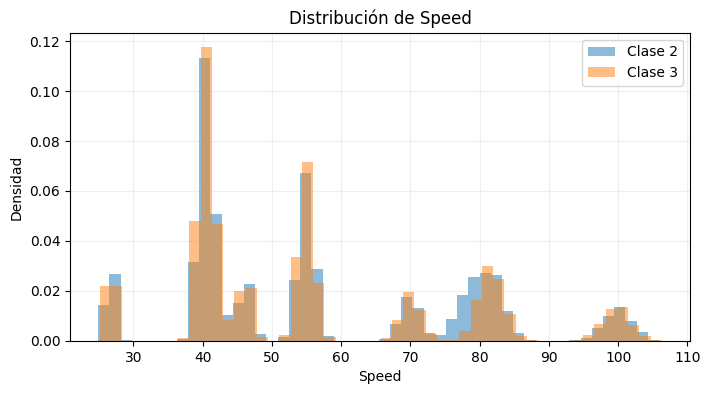

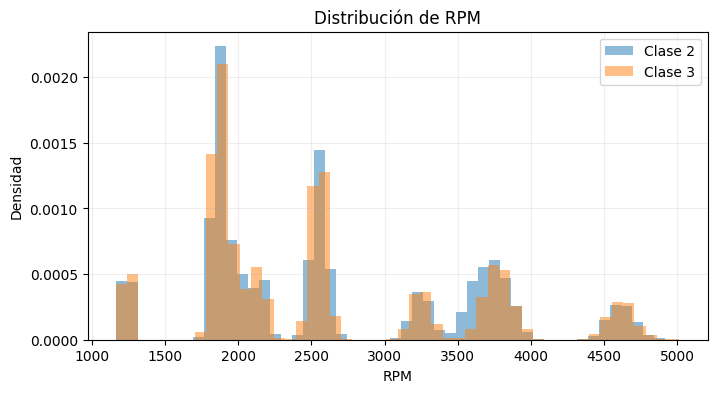

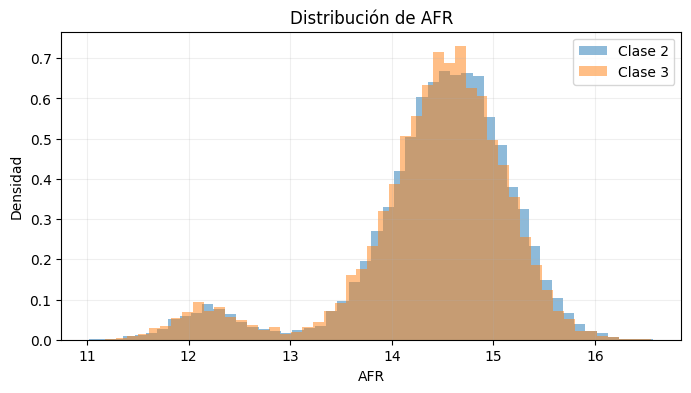

In [10]:

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('/content/EngineFaultDB_Final.csv')

features = [
    'O2',
    'CO2',
    'Consumption L/100KM',
    'Speed',
    'RPM',
    'AFR'
]

class2 = df[df['Fault'] == 2]
class3 = df[df['Fault'] == 3]

for feature in features:

    plt.figure(figsize=(8, 4))

    plt.hist(
        class2[feature],
        bins=50,
        density=True,
        alpha=0.5,
        label='Clase 2'
    )

    plt.hist(
        class3[feature],
        bins=50,
        density=True,
        alpha=0.5,
        label='Clase 3'
    )

    plt.title(f'Distribución de {feature}')
    plt.xlabel(feature)
    plt.ylabel('Densidad')
    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()


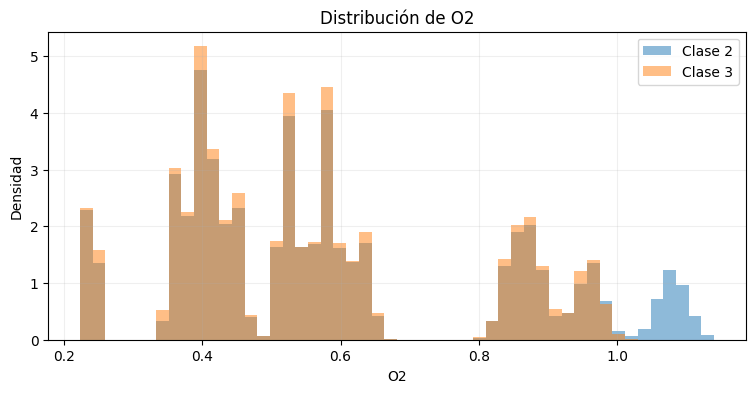

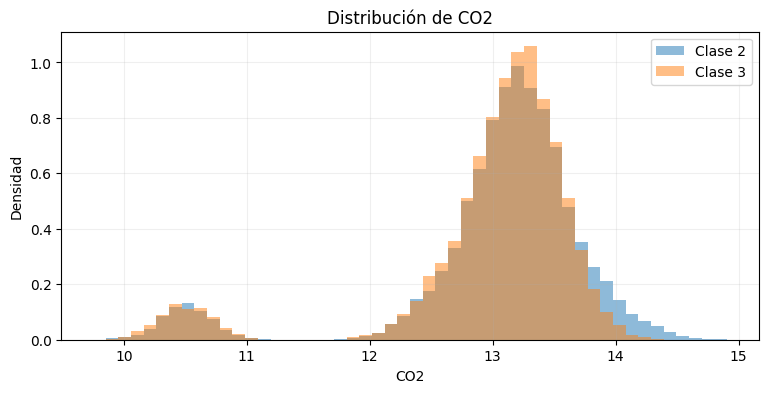

In [11]:

import numpy as np
import matplotlib.pyplot as plt

features = ['O2', 'CO2']

for feature in features:

    x2 = class2[feature].dropna()
    x3 = class3[feature].dropna()

    # Intervalos compartidos
    bins = np.histogram_bin_edges(
        np.concatenate([x2, x3]),
        bins=50
    )

    plt.figure(figsize=(9, 4))

    plt.hist(
        x2,
        bins=bins,
        density=True,
        alpha=0.5,
        label='Clase 2'
    )

    plt.hist(
        x3,
        bins=bins,
        density=True,
        alpha=0.5,
        label='Clase 3'
    )

    plt.title(f'Distribución de {feature}')
    plt.xlabel(feature)
    plt.ylabel('Densidad')
    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()


In [12]:

# Dividimos O2 en intervalos compartidos
bins = np.histogram_bin_edges(
    df.loc[df['Fault'].isin([2, 3]), 'O2'].dropna(),
    bins=30
)

analysis = df[df['Fault'].isin([2, 3])].copy()

analysis['O2_interval'] = pd.cut(
    analysis['O2'],
    bins=bins,
    include_lowest=True
)

table = pd.crosstab(
    analysis['O2_interval'],
    analysis['Fault']
)

table['Total'] = table.sum(axis=1)

table['% Clase 2'] = (
    table[2] / table['Total'] * 100
)

table['% Clase 3'] = (
    table[3] / table['Total'] * 100
)

display(table.round(2))


Fault,2,3,Total,% Clase 2,% Clase 3
O2_interval,,,,,
"(0.222, 0.254]",999,997,1996,50.05,49.95
"(0.254, 0.284]",1,3,4,25.00,75.00
"(0.315, 0.345]",22,31,53,41.51,58.49
"(0.345, 0.376]",984,986,1970,49.95,50.05
"(0.376, 0.406]",1802,1801,3603,50.01,49.99
"(0.406, 0.437]",1239,1222,2461,50.35,49.65
"(0.437, 0.468]",928,938,1866,49.73,50.27
"(0.468, 0.498]",44,40,84,52.38,47.62
"(0.498, 0.529]",1204,1210,2414,49.88,50.12


In [13]:

import pandas as pd

features = [
    'O2', 'CO2', 'RPM', 'Speed',
    'AFR', 'Lambda', 'MAP',
    'Consumption L/100KM'
]

# Definimos los tres grupos
grupo_2_alto = df[
    (df['Fault'] == 2) & (df['O2'] > 1.018)
]

grupo_2_normal = df[
    (df['Fault'] == 2) & (df['O2'] <= 1.018)
]

grupo_3 = df[df['Fault'] == 3]

# Comparamos sus medias
comparacion = pd.DataFrame({
    'Clase 2 - O2 alto': grupo_2_alto[features].mean(),
    'Clase 2 - O2 normal': grupo_2_normal[features].mean(),
    'Clase 3': grupo_3[features].mean()
})

display(comparacion.round(4))


,Clase 2 - O2 alto,Clase 2 - O2 normal,Clase 3
O2,1.0796,0.5565,0.5564
CO2,14.0066,12.9717,12.9737
RPM,3601.1722,2566.0785,2566.6286
Speed,77.6856,55.2953,55.2996
AFR,15.0447,14.3880,14.3900
Lambda,1.0234,0.9788,0.9789
MAP,1.6020,1.7956,1.7956
Consumption L/100KM,5.6468,8.5153,8.5128


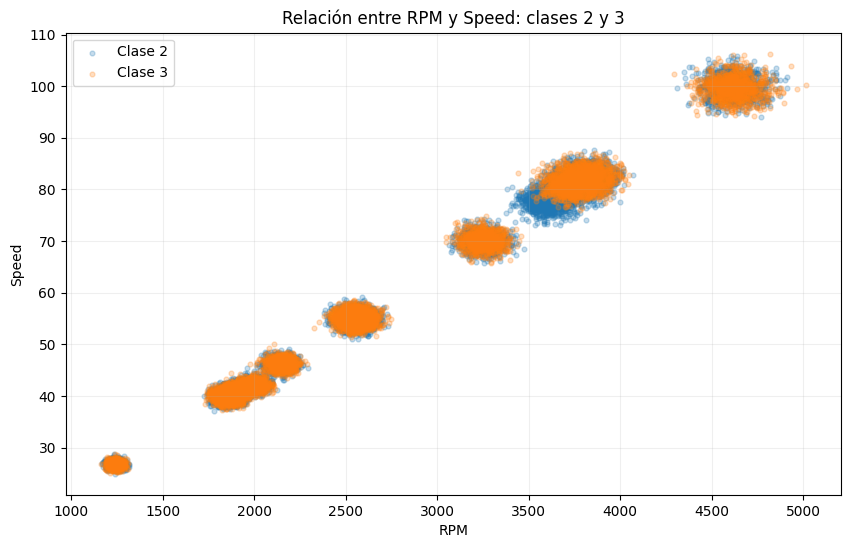

In [14]:

import matplotlib.pyplot as plt

clase2 = df[df['Fault'] == 2]
clase3 = df[df['Fault'] == 3]

plt.figure(figsize=(10, 6))

plt.scatter(
    clase2['RPM'],
    clase2['Speed'],
    alpha=0.25,
    s=12,
    label='Clase 2'
)

plt.scatter(
    clase3['RPM'],
    clase3['Speed'],
    alpha=0.25,
    s=12,
    label='Clase 3'
)

plt.xlabel('RPM')
plt.ylabel('Speed')
plt.title('Relación entre RPM y Speed: clases 2 y 3')
plt.legend()
plt.grid(alpha=0.2)
plt.show()


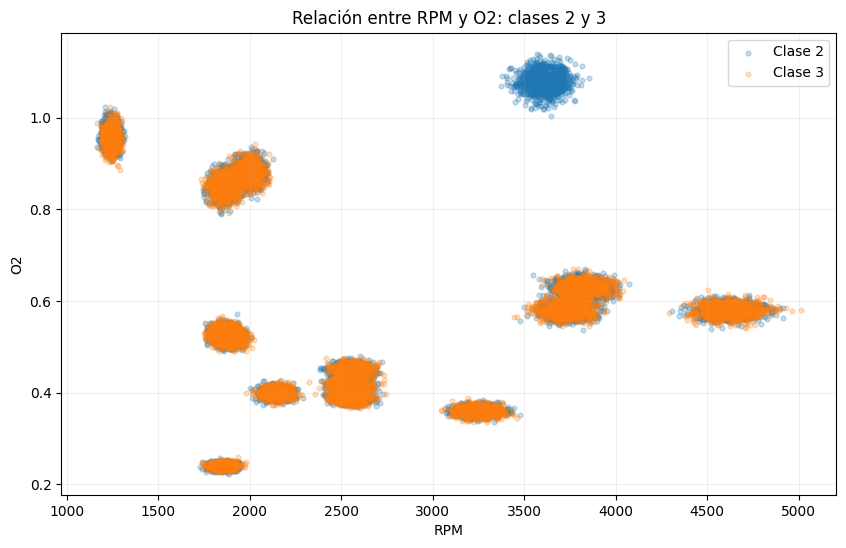

In [15]:

plt.figure(figsize=(10, 6))

plt.scatter(
    clase2['RPM'],
    clase2['O2'],
    alpha=0.25,
    s=12,
    label='Clase 2'
)

plt.scatter(
    clase3['RPM'],
    clase3['O2'],
    alpha=0.25,
    s=12,
    label='Clase 3'
)

plt.xlabel('RPM')
plt.ylabel('O2')
plt.title('Relación entre RPM y O2: clases 2 y 3')
plt.legend()
plt.grid(alpha=0.2)
plt.show()


In [16]:

import pandas as pd
import numpy as np

data = df[df['Fault'].isin([2, 3])].copy()

# Intervalos de RPM compartidos
bins_rpm = np.arange(
    data['RPM'].min() // 500 * 500,
    (data['RPM'].max() // 500 + 2) * 500,
    500
)

data['RPM_interval'] = pd.cut(
    data['RPM'],
    bins=bins_rpm,
    include_lowest=True
)

# Cantidad de observaciones por clase y régimen
conteos = pd.crosstab(
    data['RPM_interval'],
    data['Fault']
)

# Estadísticas de O2 dentro de cada régimen
estadisticas = data.groupby(
    ['RPM_interval', 'Fault'],
    observed=True
)['O2'].agg(
    ['count', 'mean', 'median', 'std']
).round(4)

display(conteos)
display(estadisticas)


Fault,2,3
RPM_interval,,
"(999.999, 1500.0]",1000,1000
"(1500.0, 2000.0]",4517,4547
"(2000.0, 2500.0]",1936,1906
"(2500.0, 3000.0]",2547,2547
"(3000.0, 3500.0]",1069,1002
"(3500.0, 4000.0]",2923,1983
"(4000.0, 4500.0]",121,107
"(4500.0, 5000.0]",887,908
"(5000.0, 5500.0]",0,1


count    mean  median     std
RPM_interval      Fault                               
(999.999, 1500.0] 2       1000  0.9610   0.961  0.0193
                  3       1000  0.9585   0.960  0.0190
(1500.0, 2000.0]  2       4517  0.5746   0.529  0.2313
                  3       4547  0.5770   0.529  0.2320
(2000.0, 2500.0]  2       1936  0.5242   0.407  0.2062
                  3       1906  0.5176   0.406  0.2022
(2500.0, 3000.0]  2       2547  0.4202   0.421  0.0259
                  3       2547  0.4206   0.421  0.0262
(3000.0, 3500.0]  2       1069  0.4060   0.361  0.1753
                  3       1002  0.3602   0.360  0.0120
(3500.0, 4000.0]  2       2923  0.7562   0.628  0.2230
                  3       1983  0.6050   0.603  0.0275
(4000.0, 4500.0]  2        121  0.5821   0.580  0.0164
                  3        107  0.5860   0.581  0.0200
(4500.0, 5000.0]  2        887  0.5798   0.580  0.0115
                  3        908  0.5799   0.580  0.0117
(5000.0, 5500.0]  3          1  0.5800   0.580     NaN